In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from scipy.ndimage import convolve, gaussian_filter


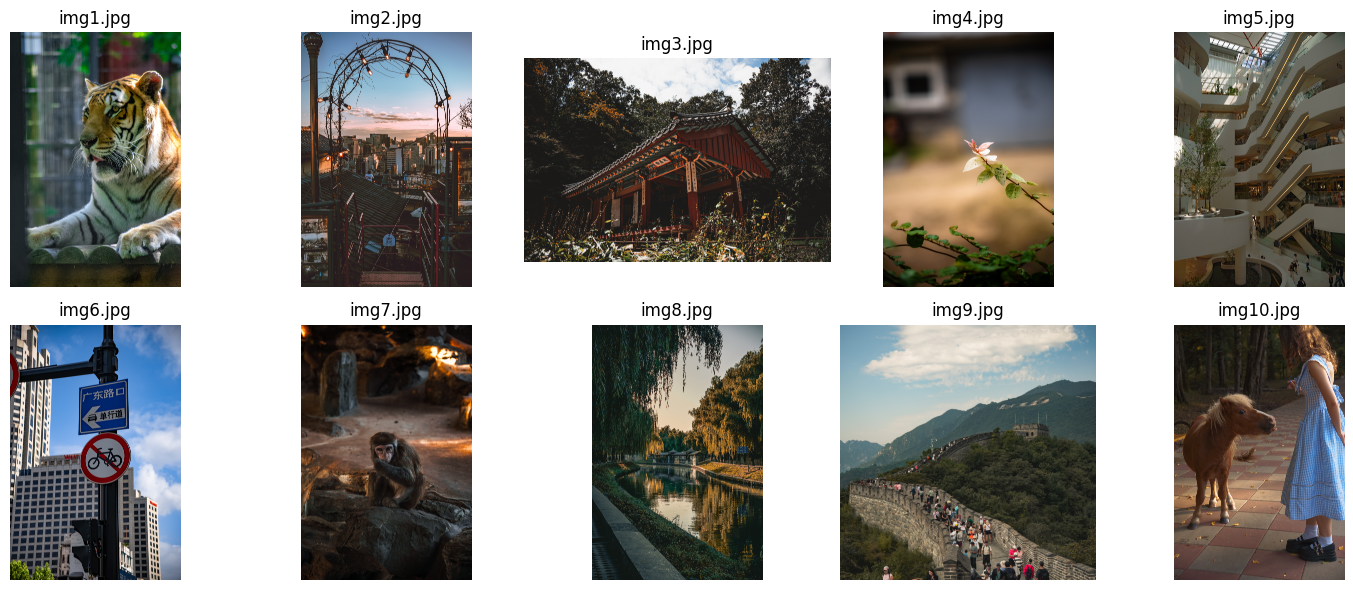

In [2]:

image_paths = [
    os.path.join("img", f"img{i}.jpg")
    for i in range(1, 11)
]

# Plot for reference
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, path in zip(axes.flat, image_paths):
    if os.path.exists(path):
        ax.imshow(Image.open(path))
        ax.set_title(os.path.basename(path))
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:


images = {}

# Load images and downsize them for speed of computation
for path in image_paths:
    if os.path.exists(path):
        image = Image.open(path).convert("RGB")
        image = image.resize(
            (image.width // 2, image.height // 2),
            Image.Resampling.LANCZOS
        )
        images[os.path.basename(path)] = np.array(
            image, dtype=np.float64
        ) / 255.0



In [8]:

# functions needed for the gaussian derivative edge detection


def create_kernel(size, sigma):
   

    radius = size // 2

    coordinates = np.arange(-radius, radius + 1, dtype=float)
    x, y = np.meshgrid(coordinates, coordinates)

    gaussian = np.exp(
        -(x**2 + y**2) / (2 * sigma**2)
    )

    # This math if from the internet
    gaussian /= gaussian.sum()

    
    kernel_x = -(x / sigma**2) * gaussian
    kernel_y = -(y / sigma**2) * gaussian

    
    kernel_x -= kernel_x.mean()
    kernel_y -= kernel_y.mean()

    return kernel_x, kernel_y



def convolveXY(image, size=3, sigma=1.0):


    kernel_x, kernel_y = create_kernel(
        size, sigma
    )

    gradient_x = convolve(image, kernel_x, mode="reflect")
    gradient_y = convolve(image, kernel_y, mode="reflect")

    magnitude = np.sqrt(gradient_x**2 + gradient_y**2)

    return magnitude



    


In [ ]:



# Apply GD on all 3 channels and combine the results
def GD(image, size, sigma):
    channel_edges = np.array([
        convolveXY(image[:, :, 0], size=size, sigma=sigma),
        convolveXY(image[:, :, 1], size=size, sigma=sigma),
        convolveXY(image[:, :, 2], size=size, sigma=sigma)
    ])

    return np.sqrt(np.sum(channel_edges**2, axis=0))


# Generalized Boundaries (Gb), color-only filtering version
def Gb(image, size, sigma, epsilon=1.0):
    r = size // 2
    y, x = np.mgrid[-r:r+1, -r:r+1]
    distance = np.sqrt(x**2 + y**2)

    # Project coordinates onto a disk of radius epsilon
    factor = np.ones_like(distance)
    mask = distance > epsilon
    factor[mask] = epsilon / distance[mask]

    px = x * factor
    py = y * factor

    # Squared Gaussian spatial weights
    weights = np.exp(-(x**2 + y**2) / sigma**2)
    alpha = np.sum(weights * px**2)

    if alpha <= 1e-12:
        return np.zeros(image.shape[:2])

    kx = weights * px / alpha
    ky = weights * py / alpha

    gx = np.array([
        convolve(image[:, :, ch], kx, mode="reflect")
        for ch in range(3)
    ])
    gy = np.array([
        convolve(image[:, :, ch], ky, mode="reflect")
        for ch in range(3)
    ])


    a = np.sum(gx**2, axis=0)
    b = np.sum(gx * gy, axis=0)
    c = np.sum(gy**2, axis=0)

    lam = 0.5 * (a + c + np.sqrt((a - c)**2 + 4*b**2))

    return np.sqrt(np.maximum(lam, 0))



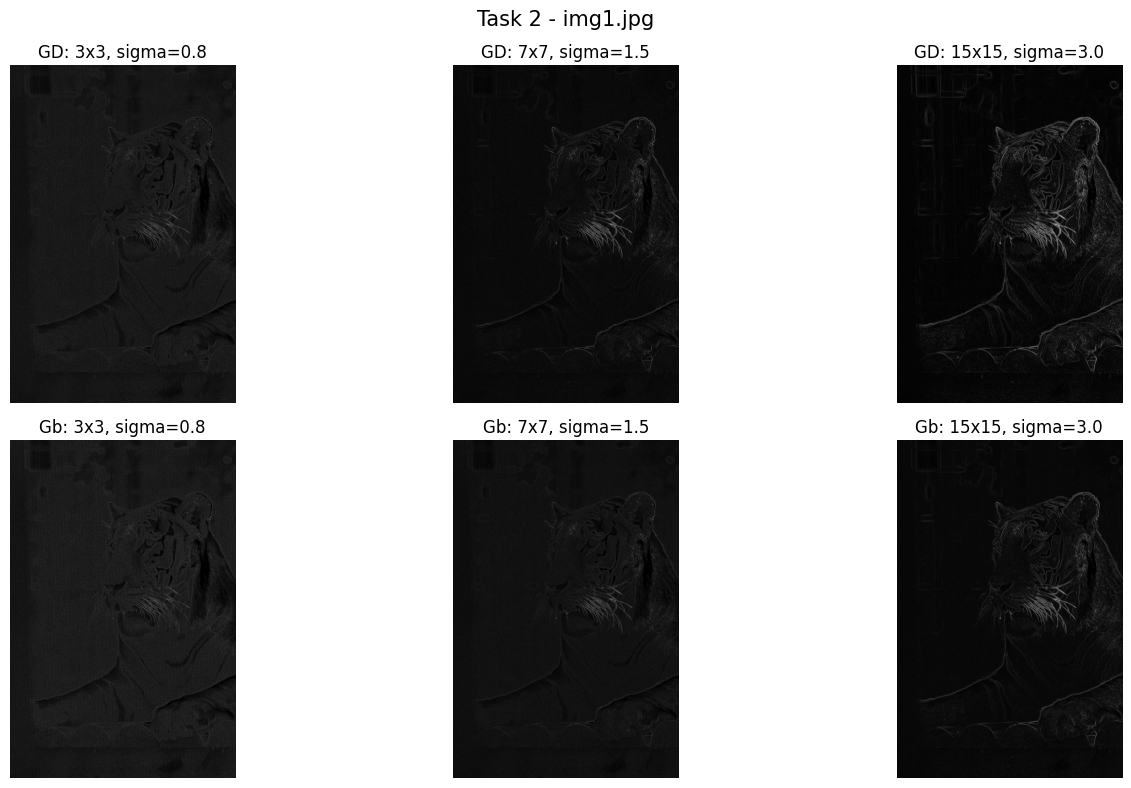

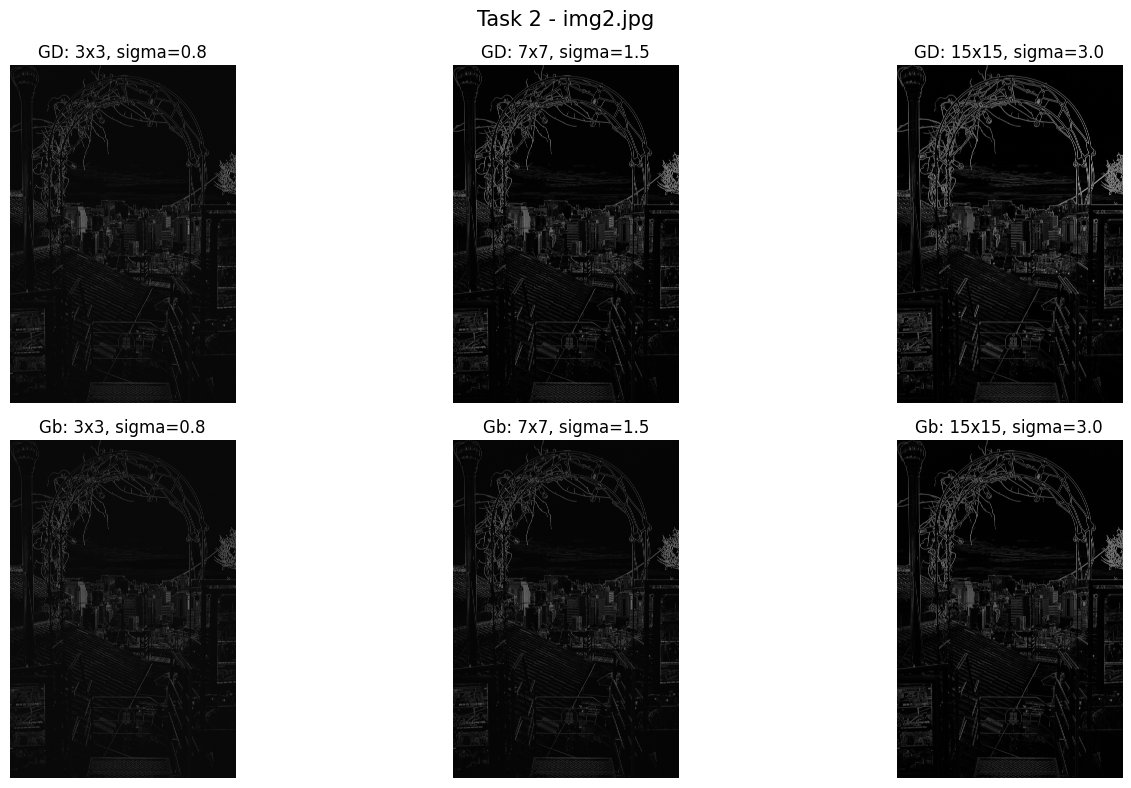

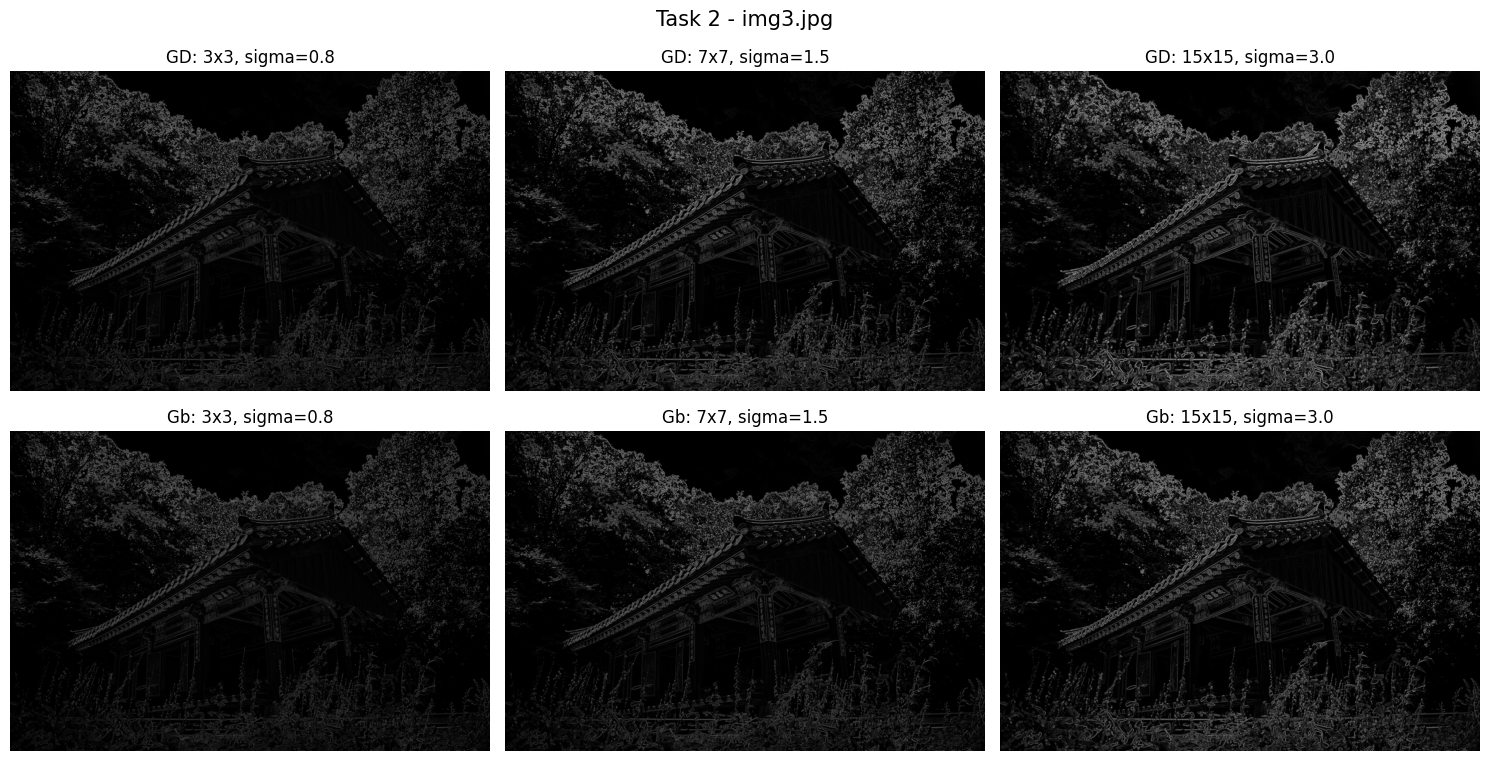

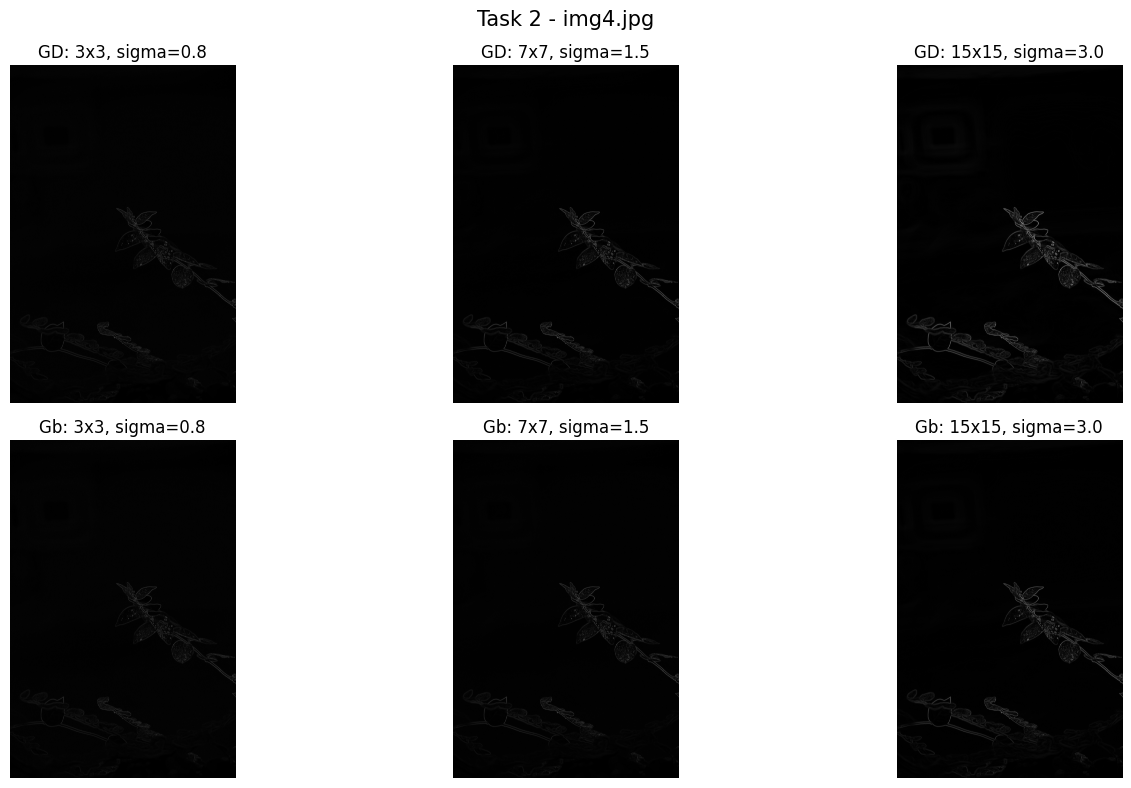

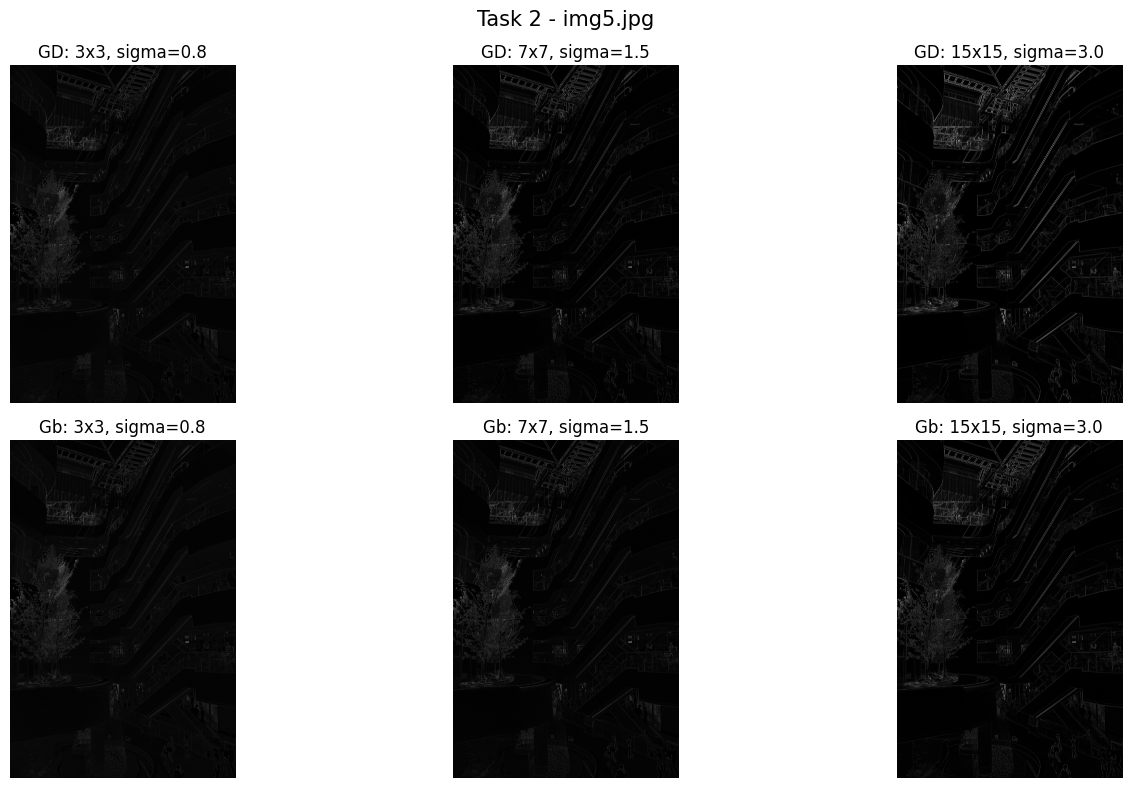

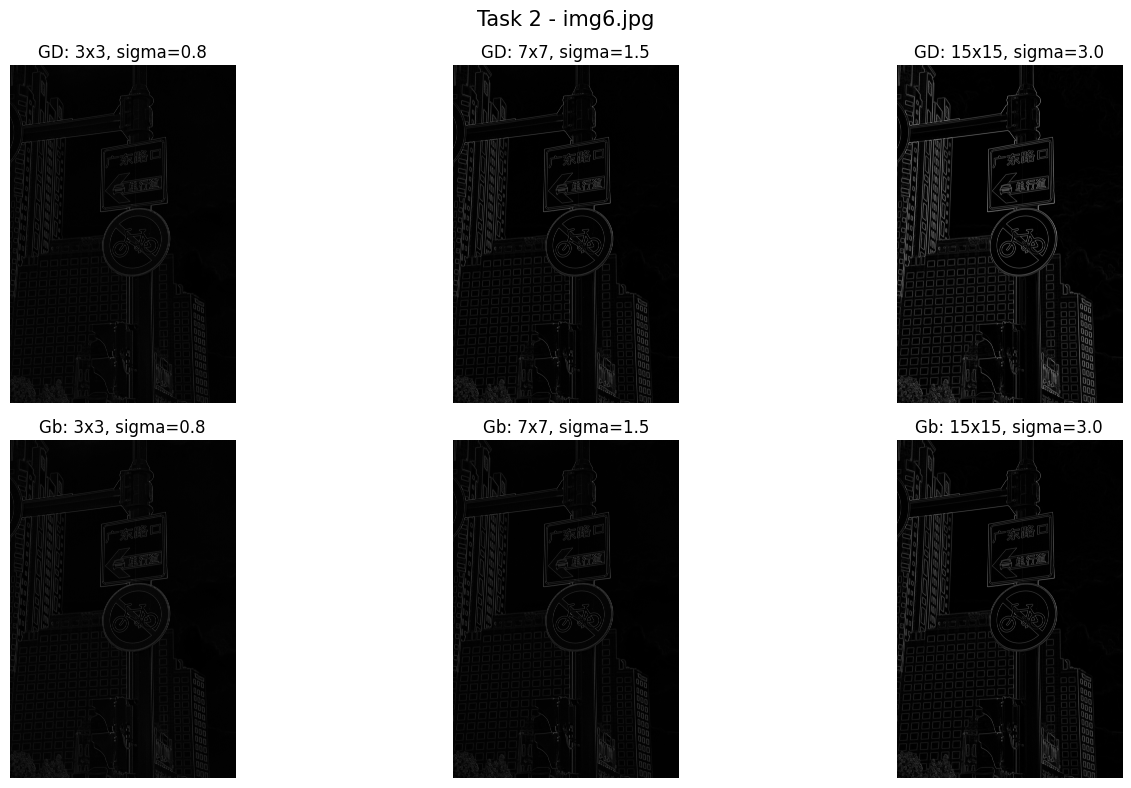

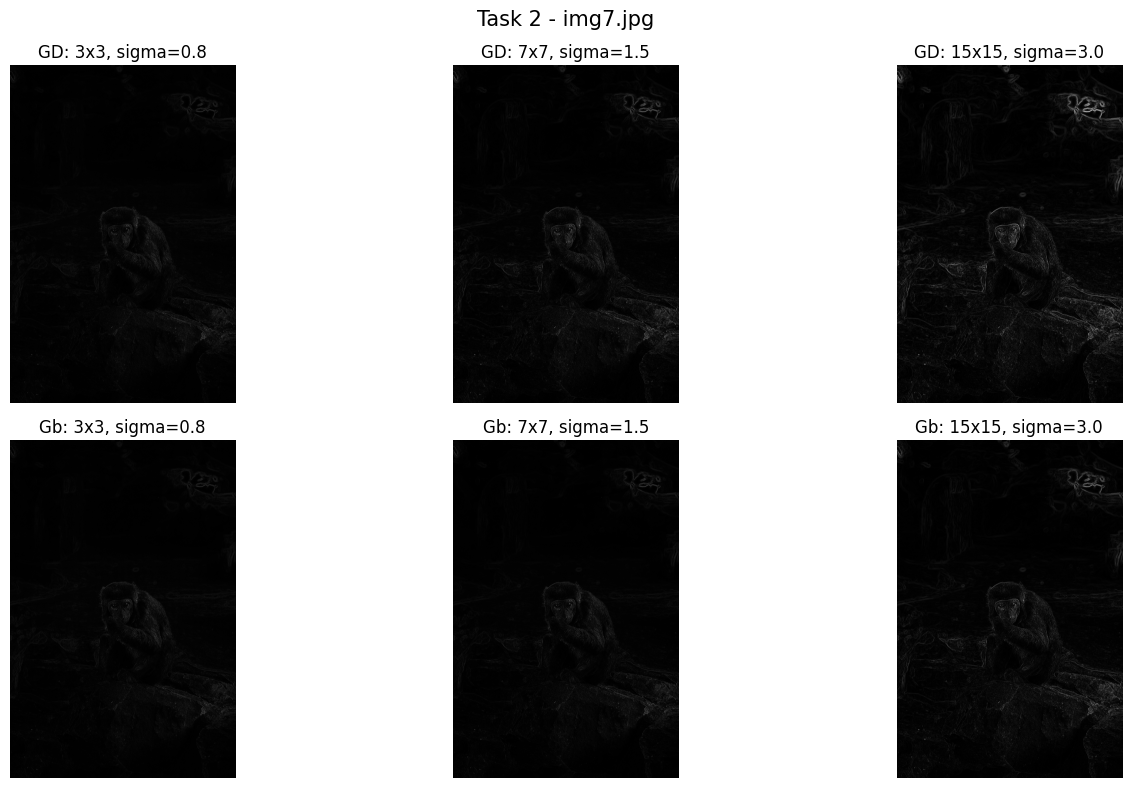

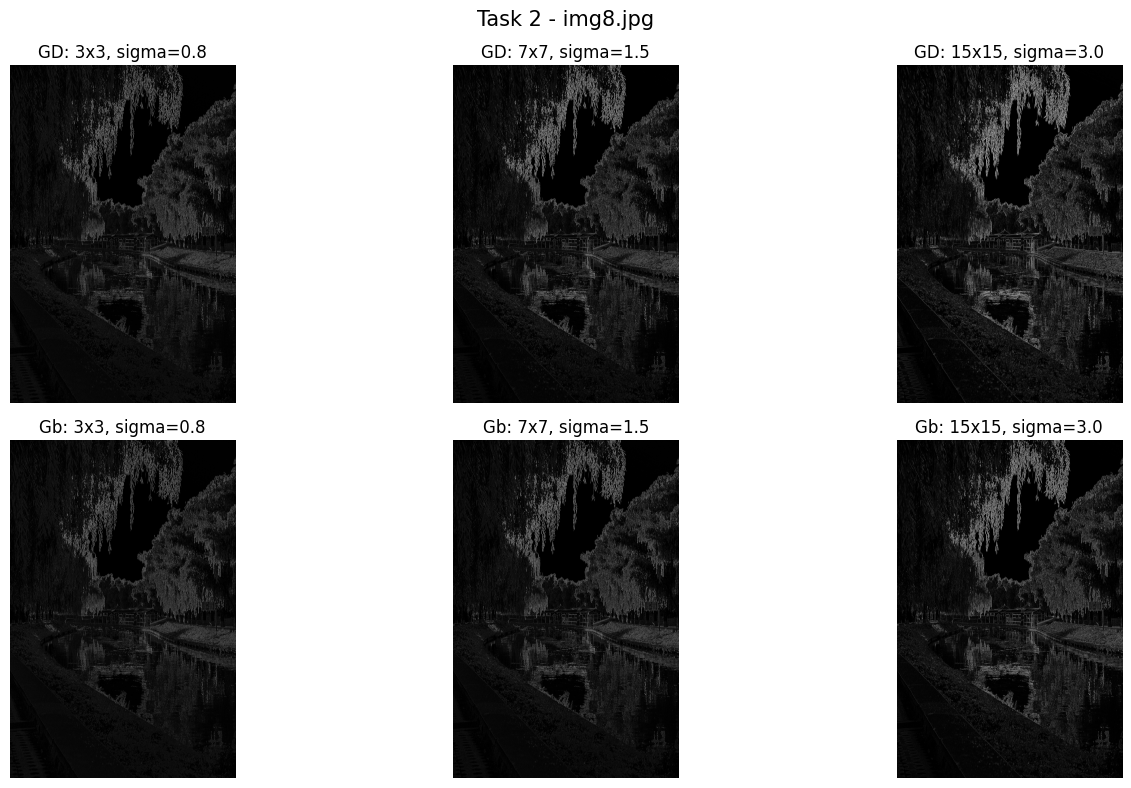

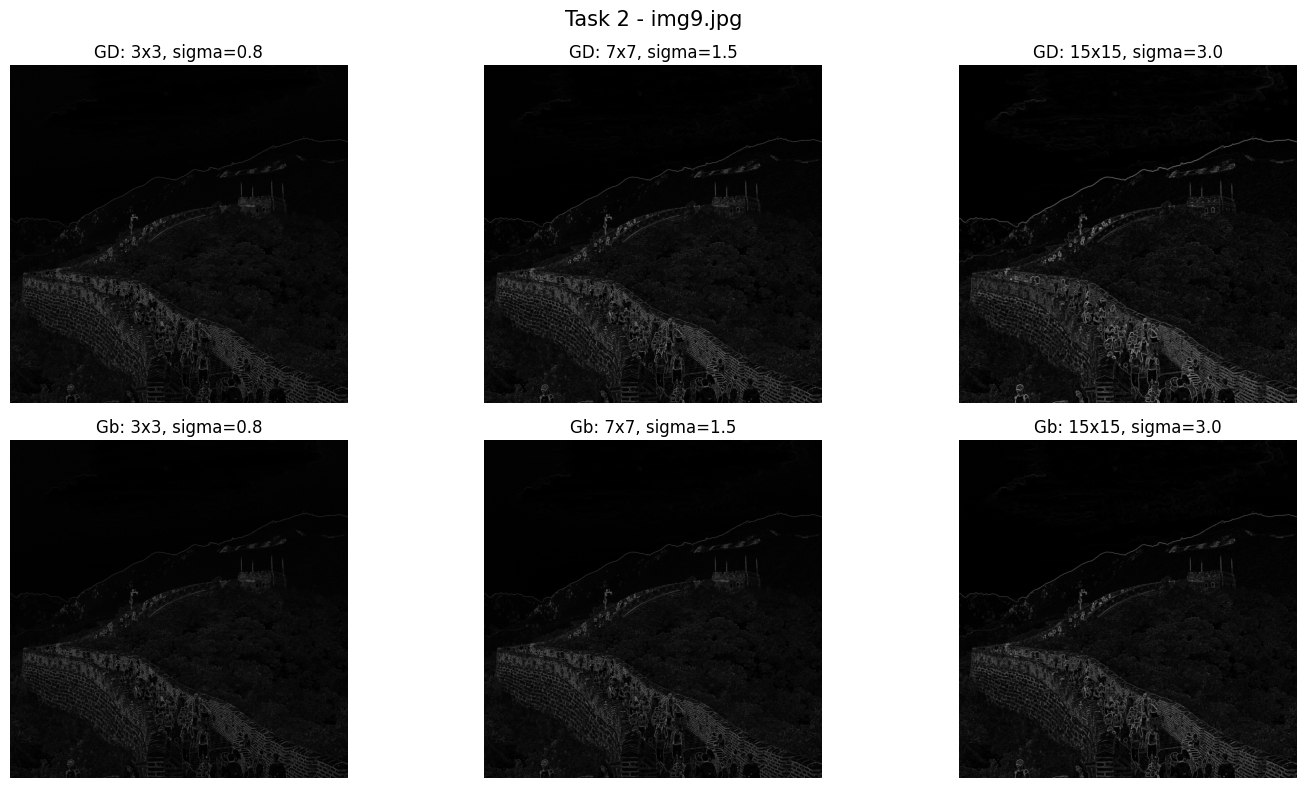

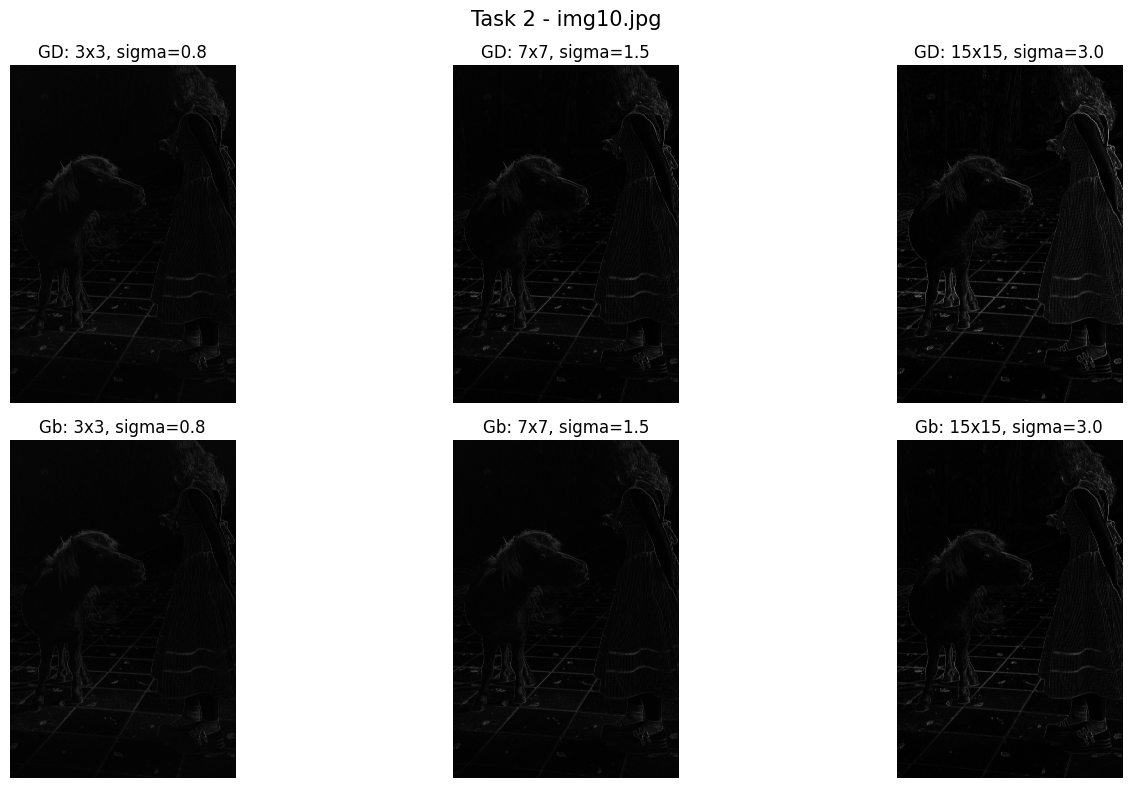

In [13]:

scales = [(3, 0.8), (7, 1.5), (15, 3.0)]
# Compare both detectors at all scales
for name, image in rgb_images.items():
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))

    for col, (size, sigma) in enumerate(scales):
        for row, (detector, label) in enumerate([
            (GD, "GD"),
            (Gb, "Gb")
        ]):
            result = detector(image, size, sigma)
            maximum = result.max()

            if maximum > 0:
                result = result / maximum

            axes[row, col].imshow(result, cmap="gray", vmin=0, vmax=1)
            axes[row, col].set_title(
                f"{label}: {size}x{size}, sigma={sigma}"
            )
            axes[row, col].axis("off")

    fig.suptitle(f"Task 2 - {name}", fontsize=15)
    plt.tight_layout()
    plt.show()